In [1]:
from environment import WumpusEnv
from q_agent import WumpusAgent
from tqdm import tqdm
from matplotlib import pyplot as plt
import numpy as np
import gymnasium as gym

In [12]:
learning_rate = 0.01        # How fast to learn (higher = faster but less stable)
n_episodes = 100   # Number of games to practice
start_epsilon = 1.0         # Start with 100% random actions
epsilon_decay = start_epsilon / (n_episodes / 2)  # Reduce exploration over time
final_epsilon = 0.01        # Always keep some exploration
num_training_maps = 10     # int n or "inf"

env = gym.wrappers.RecordEpisodeStatistics(WumpusEnv(num_training_maps=num_training_maps), buffer_length=50000)
agent = WumpusAgent(
    env=env,
    learning_rate=learning_rate,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon
)

In [13]:
for episode in tqdm(range(n_episodes)):
    # Generate new enviroment
    obs, info = env.reset()
    done = False

    # Play until agent dies or finds gold
    while not done:
        # Agent chooses action (initially random, gradually more intelligent)
        action = agent.get_action(obs)

        # Take action and observe result
        next_obs, reward, terminated, truncated, info = env.step(action)

        next_obs_bytes = next_obs
        # Learn from this experience
        agent.update(obs, action, reward, terminated, next_obs)

        # Move to next state
        done = terminated or truncated
        obs = next_obs

    # Reduce exploration rate (agent becomes less random over time)
    agent.decay_epsilon()

100%|██████████| 100/100 [00:00<00:00, 3427.92it/s]


In [14]:
def get_moving_avgs(arr, window, convolution_mode):
    """Compute moving average to smooth noisy data."""
    return np.convolve(
        np.array(arr).flatten(),
        np.ones(window),
        mode=convolution_mode
    ) / window

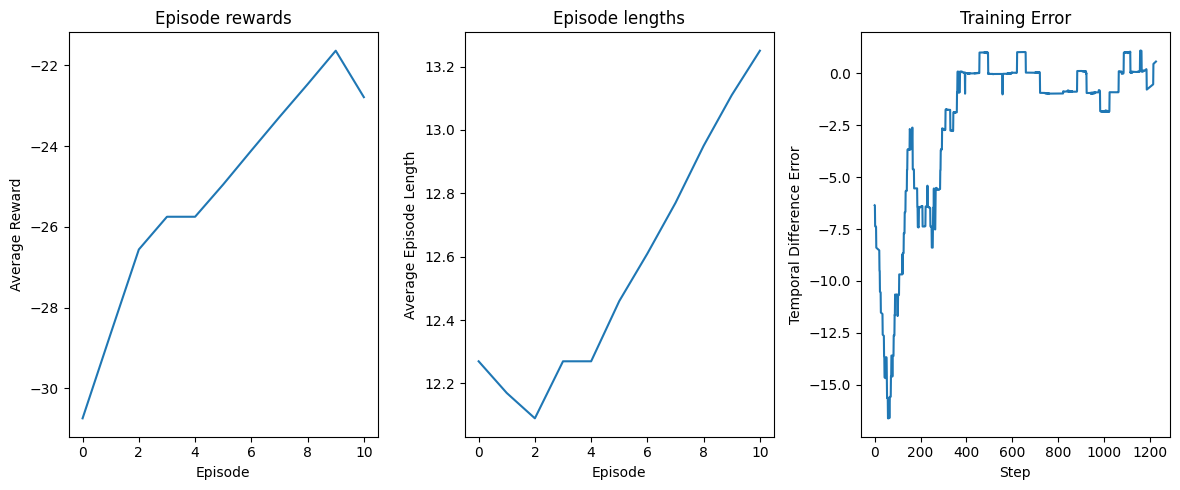

In [18]:
# Smooth over a 100-episode window
rolling_length = 100
fig, axs = plt.subplots(ncols=3, figsize=(12, 5))

# Episode rewards (win/loss performance)
axs[0].set_title("Episode rewards")
reward_moving_average = get_moving_avgs(
    env.return_queue,
    rolling_length,
    "valid"
)
axs[0].plot(range(len(reward_moving_average)), reward_moving_average)
axs[0].set_ylabel("Average Reward")
axs[0].set_xlabel("Episode")

# Episode lengths (how many actions per hand)
axs[1].set_title("Episode lengths")
length_moving_average = get_moving_avgs(
    env.length_queue,
    rolling_length,
    "valid"
)
axs[1].plot(range(len(length_moving_average)), length_moving_average)
axs[1].set_ylabel("Average Episode Length")
axs[1].set_xlabel("Episode")

# Training error (how much we're still learning)
axs[2].set_title("Training Error")
training_error_moving_average = get_moving_avgs(
    agent.training_error,
    rolling_length,
    "same"
)
axs[2].plot(range(len(training_error_moving_average)), training_error_moving_average)
axs[2].set_ylabel("Temporal Difference Error")
axs[2].set_xlabel("Step")

plt.tight_layout()
plt.show()

In [16]:
def testAgent(agent, env: WumpusEnv, num_training_maps, num_random_maps = 5):
    total_rewards_training = []
    total_rewards_random = []
    old_epsilon = agent.epsilon
    agent.epsilon = 0.0


    #Test on maps used for training

    for i in range(num_training_maps):
        obs, info = env.reset(options={"map_id":i})

        episode_reward = 0
        done = False

        while not done:
            action = agent.get_action(obs)
            obs, reward, terminated, truncated, info = env.step(action)
            episode_reward += reward
            done = terminated or truncated

        total_rewards_training.append(episode_reward)

    #Test on new random maps
    randomEnv = WumpusEnv(num_training_maps="inf")

    for i in range(num_random_maps):
        obs, info = randomEnv.reset()
        episode_reward_random = 0
        done = False

        while not done:
            action = agent.get_action(obs)
            obs, reward, terminated, truncated, info = randomEnv.step(action)
            episode_reward_random += reward
            done = terminated or truncated

        total_rewards_random.append(episode_reward_random)


    # Restore original epsilon
    agent.epsilon = old_epsilon

    win_rate = np.mean(np.array(total_rewards_training) > 0)
    average_reward = np.mean(total_rewards_training)

    #print(f"Test Results over {num_episodes} episodes:")
    print(f"Win Rate: {win_rate:.1%}")
    print(f"Average Reward: {average_reward:.3f}")
    print(f"Standard Deviation: {np.std(total_rewards_training):.3f}")

    win_rate_random = np.mean(np.array(total_rewards_random) > 0)
    average_reward_random = np.mean(total_rewards_random)

    #print(f"Test Results over {num_episodes} episodes:")
    print(f"Win Rate: {win_rate_random:.1%}")
    print(f"Average Reward: {average_reward_random:.3f}")
    print(f"Standard Deviation: {np.std(total_rewards_random):.3f}")

In [17]:
# Test your agent
print(num_training_maps)
testAgent(agent, env, num_training_maps, num_random_maps=100)

10
Win Rate: 30.0%
Average Reward: 15.600
Standard Deviation: 54.384
Win Rate: 13.0%
Average Reward: -26.690
Standard Deviation: 60.061
